# Perceptrón Multicapa - MLP  

## Fundamentos

Un **Perceptrón Multicapa (MLP)** es una red neuronal artificial *feedforward* compuesta por al menos tres capas de nodos:
1. **Capa de Entrada (Input Layer):** Recibe las características (*features*) del dataset.
2. **Capas Ocultas (Hidden Layers):** Capas intermedias que transforman las entradas mediante combinaciones lineales (Z=WTX+b) y funciones de activación no lineales ($\phi(Z)$).
3. **Capa de Salida (Output Layer):** Genera la predicción o clasificación final.

## Modelo Matemático

$$\hat{y} = \phi \left( \sum_{i=1}^{n} w_i x_i + b \right) = \phi (W^T X + b)$$

- X: Representa el vector de características de entrada a evaluar.   
- W: Representa la matriz de pesos que determinan la importancia de cada entrada.   
- b: Es el sesgo (bias) que permite desplazar la función de activación.   
- $\phi$: Representa la función de activación que introduce la no-linealidad (como ReLU o Sigmoide).
- **Backpropagation:** Algoritmo que calcula el gradiente del error respecto a cada peso y sesgo para ajustarlos mediante Descenso de Gradiente.


### Función de Activación (Relu)
$$R(z) = \max(0, z)$$
- Si la entrada es negativa (\(z < 0\)): La función devuelve 0. La neurona se "apaga" y bloquea el paso de la señal
- Si la entrada es positiva (\(z \ge 0\)): La función devuelve el valor exacto que recibió. La neurona se "activa" de forma lineal y proporcional a la fuerza de la señal.

### Función de pérdida (Entropía Cruzada Categórica)

Mide la diferencia entre la clase real y las probabilidades predichas por el modelo para cada una de las clases.

$$J(W, b) = -\frac{1}{N} \sum_{i=1}^{N} \sum_{c=1}^{M} y_{i,c} \log(\hat{y}_{i,c})$$

Donde los componentes representan lo siguiente:
- $J(W, b)$: El valor total de la pérdida (o costo) de la red, el cual el optimizador busca minimizar ajustando los pesos ($W$) y sesgos ($b$).
- $N$: El número total de patrones o muestras en el conjunto de entrenamiento.
- $M$: El número de clases posibles (3 en el caso de las especies de la flor Iris).

- $y_{i,c}$: Un indicador binario (1 o 0) de la etiqueta real que señala si la clase $c$ es la respuesta correcta para la muestra $i$.
- $\hat{y}_{i,c}$: La probabilidad predicha por la red neuronal (en la capa de salida) de que la muestra $i$ pertenezca a la clase $c$.

## Descripción de librerías, clases, funciones y parámetros

- **pandas (pd)**: carga y manipulación del dataset (read_csv, DataFrame).
- **numpy (np)**: operaciones numéricas.
- **matplotlib.pyplot (plt) y seaborn (sns)**: visualización (histogramas, dispersión, curvas).
- **sklearn.datasets.load_iris**: dataset Iris (clásico para clasificación).
- **sklearn.model_selection.train_test_split**: separar datos de entrenamiento y prueba.
- StandardScaler: escala variables.
- train_test_split: Función que divide aleatoriamente el conjunto de datos completo en una matriz de entrenamiento y otra de evaluación.
- MLPClassifier: Clase que implementa el modelo de red neuronal. Utiliza parámetros como hidden_layer_sizes (arquitectura de capas y neuronas), max_iter (límite de épocas de entrenamiento) y solver (algoritmo de optimización).
- **confusion_matrix, accuracy_score, classification_report**: métricas (matriz de confusión, accuracy, precision/recall/F1).

# Pipeline

Primero se importan las librerías, se construye un DataFrame y se verifican tamaño, clases y valores ausentes.

In [1]:
# Importar las librerías para el análisis, visualización y modelado.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay


# URL del dataset Iris público
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/iris.csv"

# Nombres de las columnas
column_names = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

# Lectura del archivo CSV usando Pandas
df = pd.read_csv(url, names=column_names)

# Mostrar las primeras filas del dataset
display(df.head())

# Separación en matrices de características (X) y etiquetas (Y)
X = df.iloc[:, 0:4] # Primeras cuatro columnas (variables independientes)
Y = df.iloc[:, 4] # Quinta columna (variable dependiente / etiqueta)

print(f"\nDimensiones de X: {X.shape}")
print(f"Clases únicas en Y: {Y.unique()}")


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa



Dimensiones de X: (150, 4)
Clases únicas en Y: ['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']


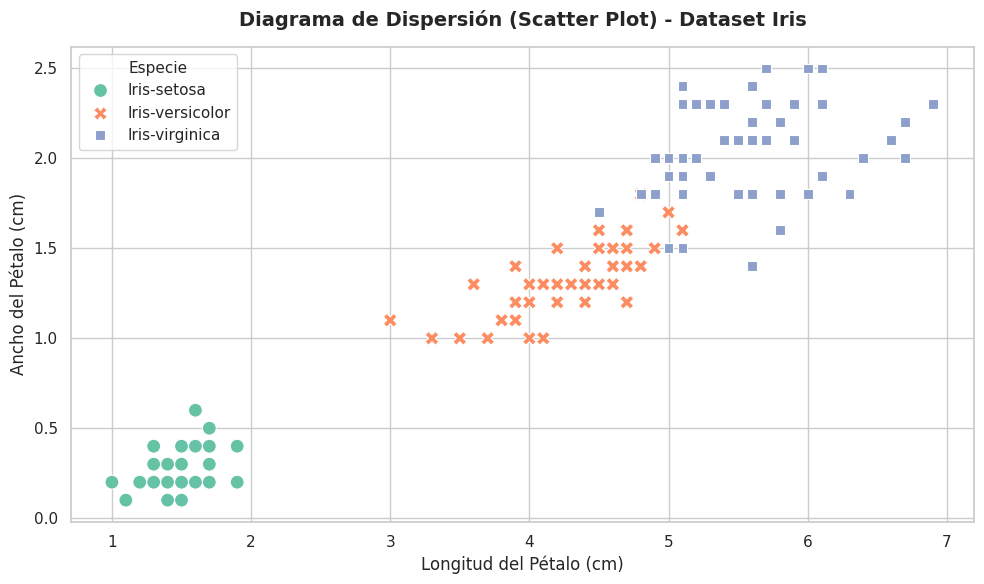

In [2]:
# Configuración del estilo visual del gráfico
sns.set_theme(style="whitegrid")

# Crear la figura de dispersión con las variables del pétalo.
plt.figure(figsize=(10,6))

# Generar el Scatter Plot utilizando Seaborn
# x e y definen las variables a comparar (ej. longitud vs ancho del pétalo)
# hue='species' asigna un color distinto a cada especie (Setosa, Versicolor, Virginica)
# palette aplica una paleta de colores didáctica y clara
sns.scatterplot(
    data=df,
    x="petal_length",
    y="petal_width",
    hue="species",
    style='species',
    palette="Set2",
    s=100             # Tamaño de los puntos
)

# Añadir títulos y etiquetas claras a los ejes
plt.title('Diagrama de Dispersión (Scatter Plot) - Dataset Iris', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Longitud del Pétalo (cm)', fontsize=12)
plt.ylabel('Ancho del Pétalo (cm)', fontsize=12)

# Ajustar la leyenda
plt.legend(title='Especie', title_fontsize='11', loc='upper left')

# Mostrar el gráfico en el notebook
plt.tight_layout()
plt.show()

## + Feature Engineering

Variables:
- X (entradas): todas las características numéricas (longitud/ancho de sépalo y pétalo).

- y (salida): la clase de la flor (setosa, versicolor y virginica).

- Se divide el dataset en entrenamiento y prueba.

- Se aplica escalado con StandardScaler, para que todas las características estén en una escala similar (muy importante para mantener los datos en un rango pequeño )

## + Preprocesamiento

In [3]:

# Train/Test split (estratificado para mantener proporciones por clase)
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.20, random_state=42, stratify=Y
)

# Escalado (fit en train, transform en train y test)
scaler = StandardScaler()

# Aprender media/desviación solo con entrenamiento y escalarlo.
X_train_scaled = scaler.fit_transform(X_train)

# Transformar prueba usando la media/desviación del entrenamiento.
X_test_scaled  = scaler.transform(X_test)

print("Datos escalados y divididos correctamente:")
print(f"Muestras de entrenamiento: {X_train_scaled.shape[0]}")
print(f"Muestras de prueba: {X_test_scaled.shape[0]}")

Datos escalados y divididos correctamente:
Muestras de entrenamiento: 120
Muestras de prueba: 30


## + Model Selection

##### Para resolver este problema utilizamos un perceptron multicapa porque el objetivo es clasificar flores de tres especies a partir de cuatro características numéricas: largo y ancho del sépalo, y largo y ancho del pétalo. Como conocemos la especie de cada muestra, se trata de un problema de aprendizaje supervisado y clasificación multiclase.
##### MLP es funcional por las siguientes características:
- Procesamiento de múltiples características: analiza simultáneamente las cuatro medidas de cada flor para realizar la clasificación.

- Clasificación multiclase: permite distinguir entre las tres especies presentes en el dataset.

- Aprendizaje mediante entrenamiento: ajusta sus pesos y sesgos para reducir los errores de predicción.




In [4]:
# Instanciación del clasificador Perceptrón Multicapa
mlp = MLPClassifier(
    hidden_layer_sizes=(10, 10),  # Arquitectura de capas ocultas.
    max_iter=1000,                 # Épocas máximas de entrenamiento
    activation="relu",           # Función de activación no lineal en capas ocultas
    solver="adam",               # Optimización por Descenso de Gradiente Adam

    random_state=42               # Semilla para reproducibilidad
)
print(mlp)



MLPClassifier(hidden_layer_sizes=(10, 10), max_iter=1000, random_state=42)


## + Model Training

Se ajusta los pesos y sesgos utilizando las características escaladas y las etiquetas verdaderas de entrenamiento. Se muestra el número de iteraciones realizadas y la pérdida final.

In [5]:
# Entrenar el modelo principal con las cuatro características.
mlp.fit(X_train_scaled, Y_train)

# Consultar cómo terminó el entrenamiento.
print("Iteraciones realizadas:", mlp.n_iter_)
print("Pérdida final:", round(mlp.loss_, 5))


Iteraciones realizadas: 605
Pérdida final: 0.05882


## + Prediction

El modelo utiliza predict() para devolver la especie predicha de las 30 flores de prueba. Se comparan las primeras diez predicciones con sus etiquetas verdaderas.

In [6]:
# Mapeo de los números a los nombres de las especies
nombres_especies = {0: 'Iris-setosa', 1: 'Iris-versicolor', 2: 'Iris-virginica'}

# Predecir clases de flores que no se usaron para entrenar.
y_pred = mlp.predict(X_test_scaled)

# Crear una tabla legible de predicciones frente a valores reales.
resultados = pd.DataFrame({
    "Especie real": Y_test.astype(str),
    "Especie predicha": y_pred.astype(str)
})
resultados["Resultado"] = resultados["Especie real"] == resultados["Especie predicha"]
display(resultados.head(10))

,Especie real,Especie predicha,Resultado
38,Iris-setosa,Iris-setosa,True
127,Iris-virginica,Iris-virginica,True
57,Iris-versicolor,Iris-versicolor,True
93,Iris-versicolor,Iris-versicolor,True
42,Iris-setosa,Iris-setosa,True
56,Iris-versicolor,Iris-versicolor,True
22,Iris-setosa,Iris-setosa,True
20,Iris-setosa,Iris-setosa,True
147,Iris-virginica,Iris-virginica,True
84,Iris-versicolor,Iris-versicolor,True


El modelo aprendio y las clasificó correctamente 29 de las 30 muestras de prueba

## + Model Evaluation

- Accuracy (exactitud): proporción global de predicciones correctas.
$$\mathrm{Accuracy}=\frac{\text{Número de predicciones correctas}}{\text{Número total de predicciones}}$$

- Matriz de confusión: la diagonal principal representa los elementos correctamente clasificados mientras los demas recuadros representan falsos posivos y falsos negativos .

- Precision, recall y F1-score: aportan información adicional sobre el rendimiento en cada especie.



Accuracy en prueba: 0.9667 (96.67 %)
Aciertos: 29 de 30

Reporte de clasificación:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



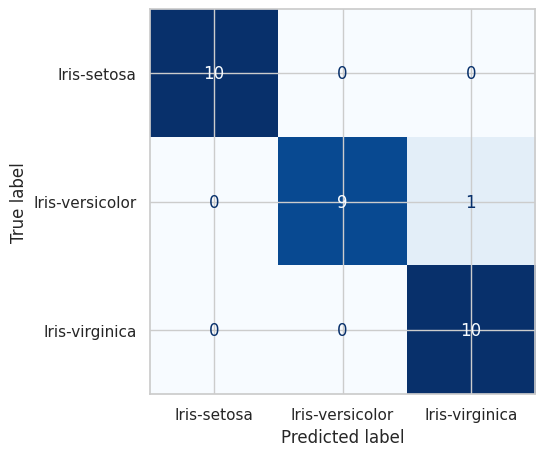

In [7]:
# Definimos las clases
clases = ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']

# Calcular la exactitud del modelo principal en el conjunto de prueba.
accuracy = accuracy_score(Y_test, y_pred)
print(f"Accuracy en prueba: {accuracy:.4f} ({accuracy*100:.2f} %)")

# Las etiquetas ya son texto, así que se comparan directamente
print(f"Aciertos: {(Y_test == y_pred).sum()} de {len(Y_test)}")

# Construir la matriz: filas = clase real; columnas = predicción.
matriz = confusion_matrix(Y_test, y_pred, labels=clases)
fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay(confusion_matrix=matriz, display_labels=clases).plot(
    ax=ax, cmap="Blues", values_format="d", colorbar=False, xticks_rotation=0
)

# Mostrar métricas adicionales para las tres clases.
print("\nReporte de clasificación:")
print(classification_report(Y_test, y_pred, labels=clases, zero_division=0))



La matriz de confusión muestra cuántas veces el modelo acertó o se equivocó por clase. El accuracy indica el porcentaje total de aciertos.

- Diagonal = aciertos; fuera de la diagonal = confusiones entre clases.
- Si la diagonal de la matriz tiene números altos y fuera de la diagonal son bajos, el modelo acierta con alta frecuencia.
- Accuracy cercano a 1.00 sugiere muy buen desempeño global en la clasificación.
- En el reporte, valores altos de precision/recall/F1 para cada clase indican que el modelo casi no confunde las especies.

## Referencias

- Leonel J. (2018, 29 de octubre). Multilayer Perceptron. Medium. Medium. https://medium.com/@jorgesleonel/multilayer-perceptron-6c5db6a8dfa3

- Baladram S. (2024, 25 de octubre). Multilayer Perceptron, Explained: A Visual Guide with Mini 2D Dataset. Medium. https://medium.com/data-science/multilayer-perceptron-explained-a-visual-guide-with-mini-2d-dataset-0ae8100c5d1c
- Kassem (2024, 10 de julio). Building a Multi-Layer Perceptron from Scratch with NumPy. Medium. https://elcaiseri.medium.com/building-a-multi-layer-perceptron-from-scratch-with-numpy-e4cee82ab06d

